In [438]:
from empi_pyspark_utils.spark_support.context import create_local_context
from empi_environments.env_prod_spark import *

spark = create_local_context(cassandra_host = CASSANDRA_HOST,cpus = 2,driver_memory = '512M')

In [439]:
import pyspark.sql.functions as f
from pyspark.sql.functions import udf

@udf
def project_type(path):
    if path.endswith('-dag'):
        return 'dag'
    elif path.endswith('-pipeline'):
        return 'pipeline'
    elif 'feed-features' in path or path.endswith('assembly'):
        return 'assembly'
    elif (path.startswith('empirica-algo/installers') and path.endswith('-installer')) or path.endswith('infrastructure-installer'):
        return 'installer'
    
    return 'code'

projects = spark.read.json('../data/gitlab-projects.json')\
.withColumn('name_with_namespace',f.regexp_replace('name_with_namespace', ' ', ''))\
.withColumn('project_type',project_type(f.col('name_with_namespace')))\
.drop('tag_list')

#projects.where(f.col('project_type')=='installer').show(truncate = False)

In [440]:
from pyspark.sql.types import TimestampType

def duration_days(start,end):
    return f.round((f.unix_timestamp(end) - f.unix_timestamp(start))/86400)

mrs = spark.read.json('../data/gitlab-merge-requests.json')\
.withColumn('created_at',f.col('created_at').cast(TimestampType()))\
.withColumn('updated_at',f.col('updated_at').cast(TimestampType()))\
.withColumn('closed_at',f.col('closed_at').cast(TimestampType()))\
.withColumn('created_at_month',f.date_trunc('month',f.col('created_at')))\
.withColumn('merged_at',f.col('merged_at').cast(TimestampType()))\
.where(f.col('state')=='merged')\
.withColumn('duration_days',duration_days('created_at','merged_at'))

mrs.printSchema()

root
 |-- author: struct (nullable = true)
 |    |-- id: long (nullable = true)
 |    |-- username: string (nullable = true)
 |-- closed_at: timestamp (nullable = true)
 |-- created_at: timestamp (nullable = true)
 |-- id: long (nullable = true)
 |-- iid: long (nullable = true)
 |-- merged_at: timestamp (nullable = true)
 |-- project_id: long (nullable = true)
 |-- source_branch: string (nullable = true)
 |-- state: string (nullable = true)
 |-- target_branch: string (nullable = true)
 |-- updated_at: timestamp (nullable = true)
 |-- user_notes_count: long (nullable = true)
 |-- created_at_month: timestamp (nullable = true)
 |-- duration_days: double (nullable = true)



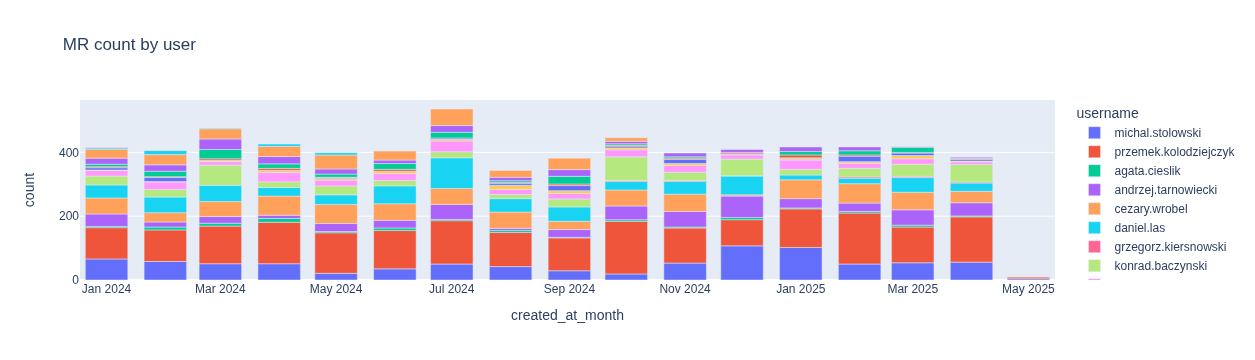

In [441]:
import plotly.express as px
import warnings

warnings.filterwarnings("ignore")

mrs_count_by_author = mrs\
.groupBy('author.username','created_at_month')\
.agg(f.count('*').alias('count'))\
.orderBy(f.col('created_at_month').desc(),f.col('username'))

px.bar(mrs_count_by_author.toPandas(),x='created_at_month',y='count',color='username',title='MR count by user',height=500)

In [458]:
project_mrs = projects.join(mrs,projects.id == mrs.project_id)

mrs_count_by_author = project_mrs\
.groupBy('author.username','created_at_month','project_type')\
.agg(f.count('*').alias('count'))\
.orderBy(f.col('created_at_month').desc(),f.col('username'))

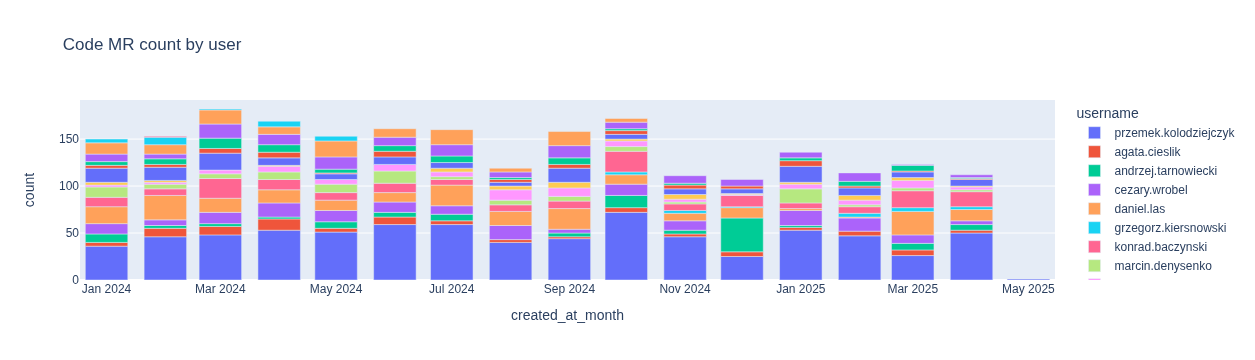

In [459]:
px.bar(
    mrs_count_by_author.where(projects.project_type=='code').toPandas(),
    x='created_at_month',
    y='count',
    color='username',
    title='Code MR count by user',
    height=500)

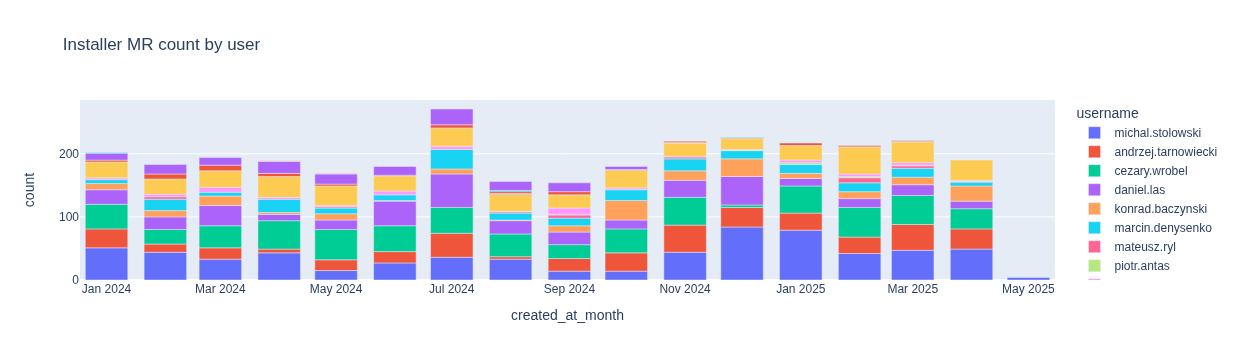

In [460]:
px.bar(
    mrs_count_by_author.where(projects.project_type=='installer').toPandas(),
    x='created_at_month',
    y='count',
    color='username',
    title='Installer MR count by user',
    height=500)

In [443]:
mrs_duration_by_user = project_mrs\
.groupBy('created_at_month','author.username','project_type')\
.agg(
    f.avg('duration_days').alias('duration_days_avg'),
    f.min('duration_days').alias('duration_days_min'),
    f.max('duration_days').alias('duration_days_max'))

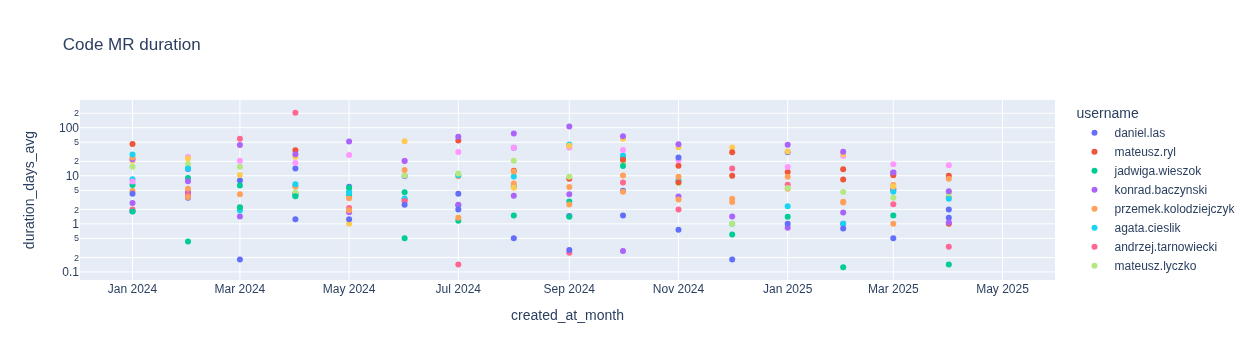

In [444]:
px.scatter(
    mrs_duration_by_user.where(f.col('project_type')=='code').toPandas(),
    x='created_at_month',
    y='duration_days_avg',
    color='username',
    title='Code MR duration',
    height=500,
    log_y=True)

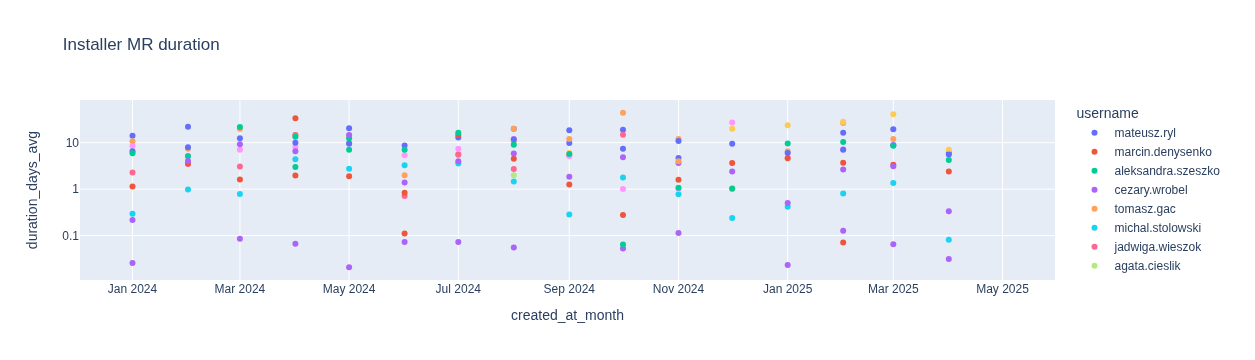

In [445]:
px.scatter(
    mrs_duration_by_user.where(f.col('project_type')=='installer').toPandas(),
    x='created_at_month',
    y='duration_days_avg',
    color='username',
    title='Installer MR duration',
    height=500,
    log_y=True)

In [446]:
mrs_comments_by_user = project_mrs\
.groupBy('created_at_month','author.username','project_type')\
.agg(
    f.count('*').alias('count'),
    f.sum('user_notes_count').alias('comments'))\
.withColumn('comments_avg',f.col('comments')/f.col('count'))

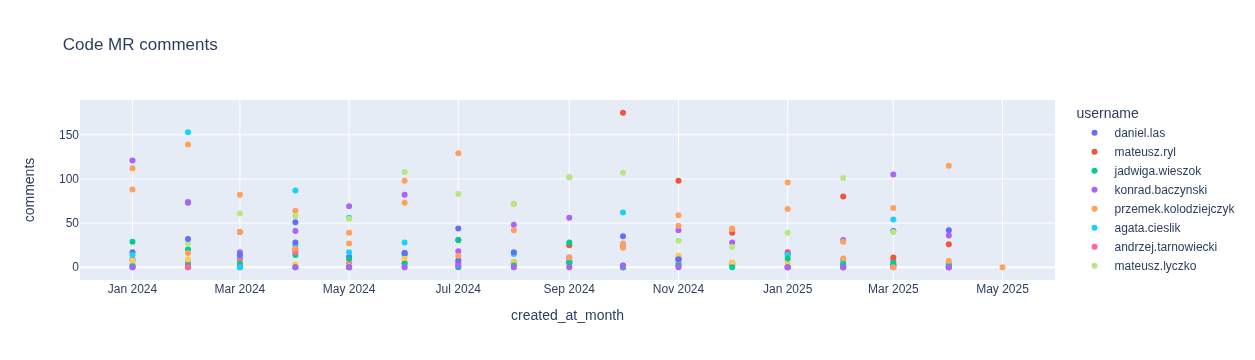

In [447]:
px.scatter(mrs_comments_by_user.where(f.col('project_type')=='code').toPandas(),x='created_at_month',y='comments',color='username',title='Code MR comments',height=500)

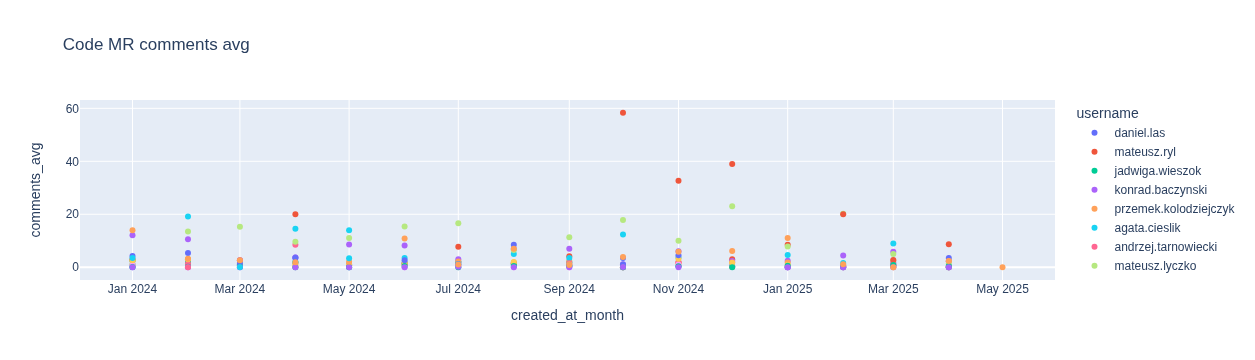

In [448]:
px.scatter(mrs_comments_by_user.where(f.col('project_type')=='code').toPandas(),x='created_at_month',y='comments_avg',color='username',title='Code MR comments avg',height=500)

In [449]:
issues = spark.read.json('../data/jira-issues-CRYP.json')

issues.printSchema()

root
 |-- changelog: struct (nullable = true)
 |    |-- histories: array (nullable = true)
 |    |    |-- element: struct (containsNull = true)
 |    |    |    |-- author: struct (nullable = true)
 |    |    |    |    |-- accountId: string (nullable = true)
 |    |    |    |    |-- displayName: string (nullable = true)
 |    |    |    |-- created: string (nullable = true)
 |    |    |    |-- id: string (nullable = true)
 |    |    |    |-- items: array (nullable = true)
 |    |    |    |    |-- element: struct (containsNull = true)
 |    |    |    |    |    |-- fieldId: string (nullable = true)
 |    |    |    |    |    |-- from: string (nullable = true)
 |    |    |    |    |    |-- fromString: string (nullable = true)
 |    |    |    |    |    |-- to: string (nullable = true)
 |    |    |    |    |    |-- toStr: string (nullable = true)
 |-- fields: struct (nullable = true)
 |    |-- created: string (nullable = true)
 |    |-- issuetype: struct (nullable = true)
 |    |    |-- id: st

In [450]:
def development_change(change):
    return (change.to == '3')

issuses_dev = issues\
.select(
    f.col('key'),
    f.col('fields.summary'),
    f.col('fields.created'),
    f.col('fields.resolutiondate'),
    f.col('fields.issuetype.name').alias('type'),
    f.col('fields.priority.name').alias('priority'),
    f.col('changelog'))\
.where(f.col('type').isin(['Bug','Story','Sub-task']))\
.withColumn('history',f.explode('changelog.histories'))\
.withColumn('changed_at',f.col('history.created'))\
.withColumn('changed_by',f.col('history.author.displayName'))\
.withColumn('change',f.explode('history.items'))\
.drop('changelog','history')\
.where(f.col('change.fieldId')=='status')\
.withColumn('created',f.col('created').cast(TimestampType()))\
.withColumn('resolutiondate',f.col('resolutiondate').cast(TimestampType()))\
.withColumn('changed_at',f.col('changed_at').cast(TimestampType()))\
.where(development_change(f.col('change')))\
.select('key','summary','created','changed_at','resolutiondate','changed_by','change.toStr','type','priority')\
.dropDuplicates(['key','changed_by'])\
.withColumn('created_month',f.date_trunc('month','created'))\
.withColumn('resolutiondate_month',f.date_trunc('month','resolutiondate'))\
.orderBy(f.col('created').desc())

issuses_dev_completed = issuses_dev.where(f.col('resolutiondate').isNotNull())

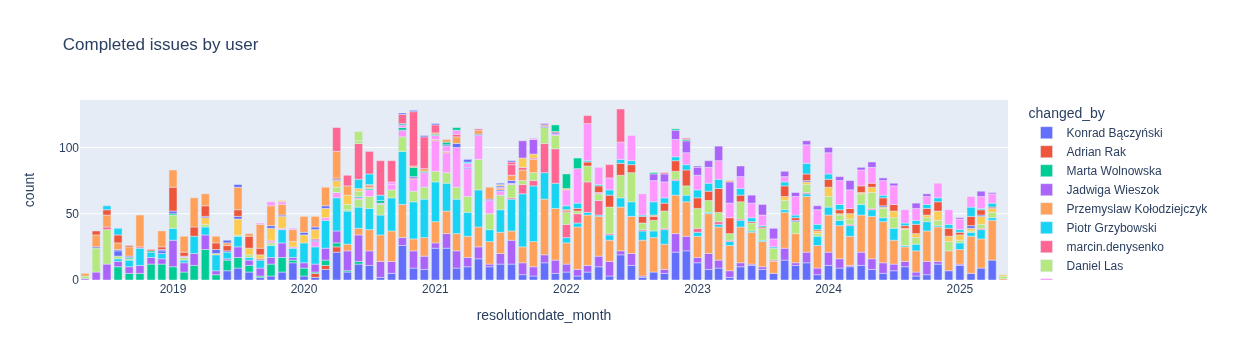

In [451]:
px.bar(
    issuses_dev_completed.groupBy('resolutiondate_month','changed_by').count().toPandas(),
    x='resolutiondate_month',
    y='count',
    color='changed_by',
    title='Completed issues by user',
    height=700)

# User drilldown

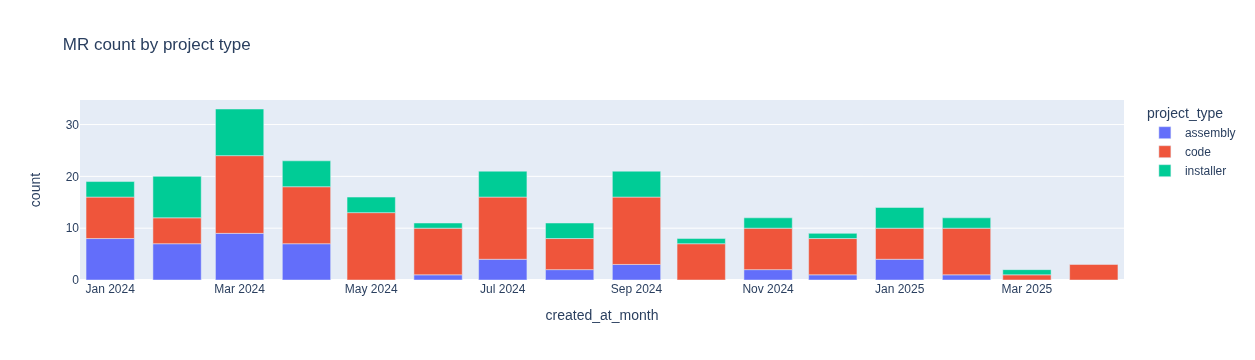

In [469]:
gitlab_user = 'tomasz.gac'
jira_user = 'Tomasz Gac'

px.bar(
    project_mrs.where(f.col('author.username')==gitlab_user).groupBy('created_at_month','project_type').count().toPandas(),
    x='created_at_month',
    y='count',
    color='project_type',
    title='MR count by project type',
    height=500)

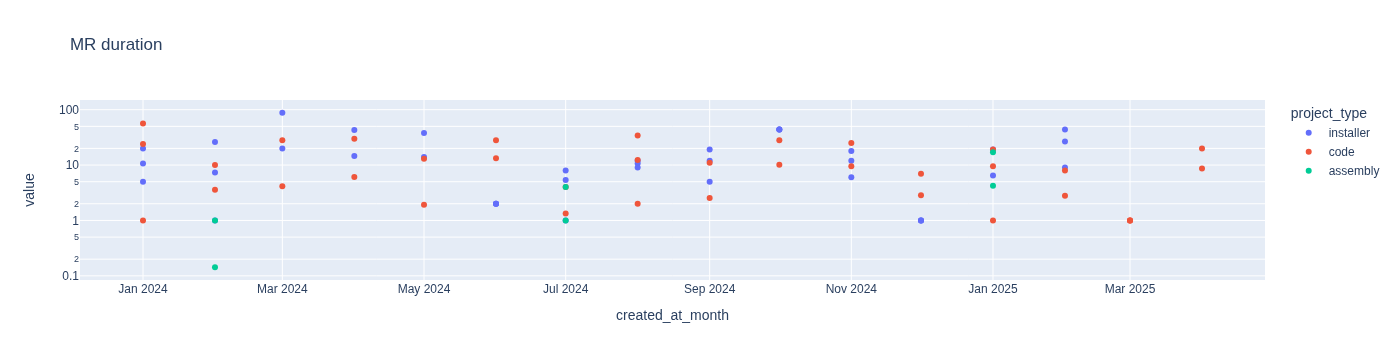

In [470]:
px.scatter(
    mrs_duration_by_user.where(f.col('username')==gitlab_user).toPandas(),
    x='created_at_month',
    y=['duration_days_avg','duration_days_min','duration_days_max'],
    color='project_type',
    title='MR duration',
    height=500,
    log_y=True)

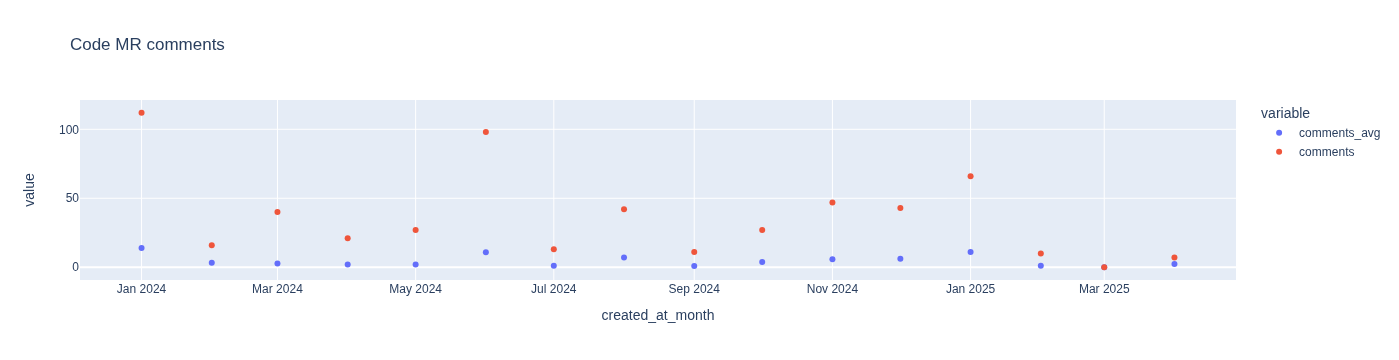

In [471]:
px.scatter(
    mrs_comments_by_user.where(f.col('username') == gitlab_user).where(f.col('project_type') == 'code').toPandas(),
    x='created_at_month',
    y=['comments_avg','comments'],
    title='Code MR comments',
    height=500)

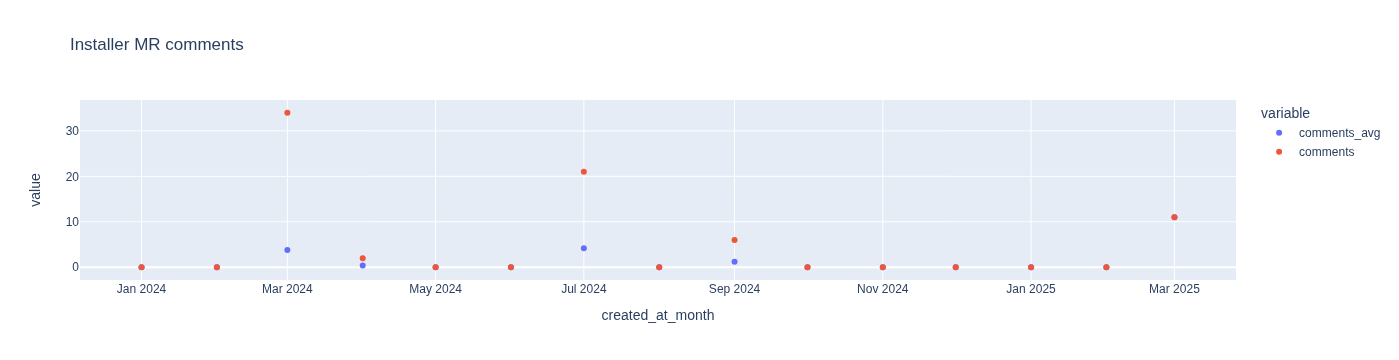

In [472]:
px.scatter(
    mrs_comments_by_user.where(f.col('username') == gitlab_user).where(f.col('project_type') == 'installer').toPandas(),
    x='created_at_month',
    y=['comments_avg','comments'],
    title='Installer MR comments',
    height=500)

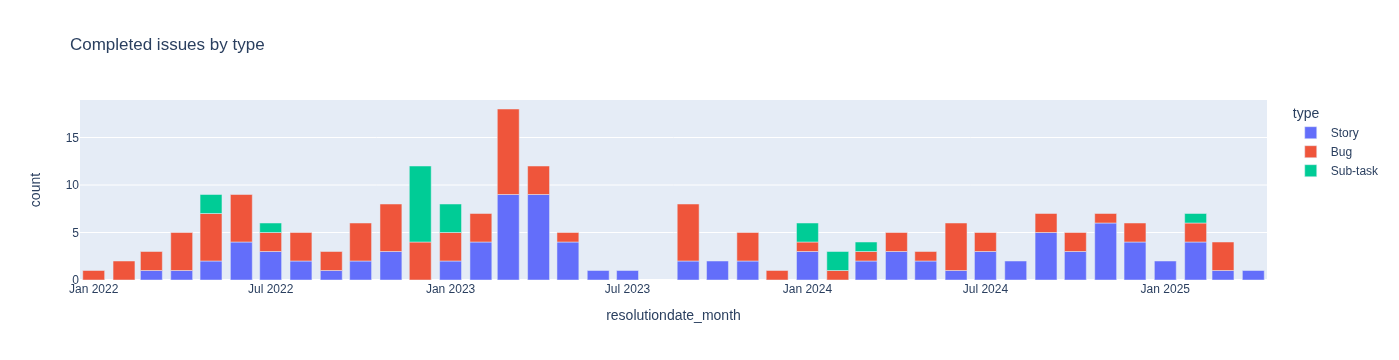

In [473]:
px.bar(
    issuses_dev_completed.groupBy('resolutiondate_month','changed_by','type').count().where(f.col('changed_by') == jira_user).toPandas(),
    x='resolutiondate_month',
    y='count',
    color='type',
    title='Completed issues by type',
    height=500)

In [477]:
import datetime
import pandas as pd

pd.set_option('display.max_rows', None)

recent_issues_dev = issuses_dev\
.where(f.col('changed_by') == jira_user)\
.where(f.col('changed_at') > datetime.datetime.now() - datetime.timedelta(days=365))\
.withColumn('duration_days',duration_days('changed_at','resolutiondate'))\
.orderBy(f.col('changed_at').desc())

recent_issues_dev.toPandas()

,key,summary,created,changed_at,resolutiondate,changed_by,toStr,type,priority,created_month,resolutiondate_month,duration_days
0,CRYP-10637,[Backtest] Wersja 1.0.12 nie działa poprawnie ...,2025-04-29 09:33:08.887,2025-04-29 10:32:06.513,NaT,Tomasz Gac,In Progress,Bug,High,2025-04-01,NaT,NaN
1,CRYP-10556,[Backtest] Zasilenie danych historycznych od p...,2025-04-09 06:20:37.166,2025-04-16 09:15:44.001,NaT,Tomasz Gac,In Progress,Story,High,2025-04-01,NaT,NaN
2,CRYP-10257,[Backtest] Wykonywanie symulacji dla listy ins...,2024-12-12 10:27:48.089,2025-04-16 08:10:56.407,NaT,Tomasz Gac,In Progress,Story,Medium,2024-12-01,NaT,NaN
3,CRYP-10459,[Backtest] Połączenie skryptów do generowania ...,2025-03-11 07:01:23.833,2025-04-14 12:18:53.291,NaT,Tomasz Gac,In Progress,Story,High,2025-03-01,NaT,NaN
4,CRYP-10520,[Backtest] Zasilenie danych historycznych od p...,2025-03-26 14:05:32.372,2025-03-31 10:22:44.185,2025-04-09 13:37:04.219,Tomasz Gac,In Progress,Story,Highest,2025-03-01,2025-04-01,9.0
5,CRYP-10286,Weryfikacja transakcji giełdowych z giełdy MEXC,2025-01-27 16:59:45.440,2025-03-05 08:59:06.112,NaT,Tomasz Gac,In Progress,Story,Medium,2025-01-01,NaT,NaN
6,CRYP-10363,[Backtest] Automatyczne nazywanie uruchomień b...,2025-02-13 11:49:45.790,2025-02-17 07:28:42.804,2025-03-05 08:07:45.393,Tomasz Gac,In Progress,Story,Medium,2025-02-01,2025-03-01,16.0
7,CRYP-10317,Brak liquidity measures dla niektórych instrum...,2025-02-05 10:04:12.986,2025-02-11 12:29:01.344,2025-03-12 13:34:28.354,Tomasz Gac,In Progress,Bug,High,2025-02-01,2025-03-01,29.0
8,CRYP-10083,Odświeżanie subskrypcji MDR w Platform Admin p...,2024-11-29 07:23:14.867,2025-02-11 12:07:52.107,NaT,Tomasz Gac,In Progress,Sub-task,Medium,2024-11-01,NaT,NaN
9,CRYP-10082,Restart adapterów feedowych i tradingowych w P...,2024-11-29 07:22:46.112,2025-02-11 12:07:47.424,NaT,Tomasz Gac,In Progress,Sub-task,Medium,2024-11-01,NaT,NaN


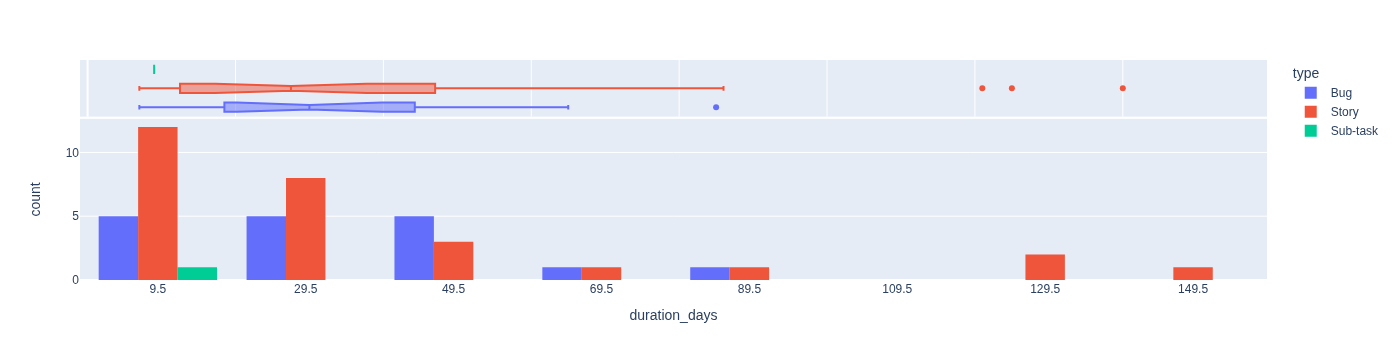

In [475]:
px.histogram(recent_issues_dev.toPandas(),x='duration_days',color='type',barmode='group',marginal='box')